<img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 6

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

**Optional reference (the "bible" by the "bishop"... pun intended 😆) :** Bishop, Christopher M. *Pattern recognition and machine learning*. Springer Verlag, 2006.

**References/resources to create this notebook:**
* [Car figure](https://korkortonline.se/en/theory/reaction-braking-stopping/)

Apologies in advance if I missed some reference used in this notebook. Please contact me if that is the case, and I will gladly include it here.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load jupyter notebook (it will open in your internet browser):
```
jupyter notebook
```
4. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

In [1]:
# Basic plotting tools needed in Python.

import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
from IPython.display import display, Math # to print with Latex math

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides

## Outline for today

* Continuation of Bayesian inference for one hidden rv: Example with Gaussian likelihood and Uniform prior (**Part II**)
    - Prior
    - Likelihood
    - Marginal likelihood
    - Posterior
    - Gaussian pdf's product

**Reading material**: This notebook + Chapter 3

## Recap of Lecture 5: car stopping distance with known $x$

We focused on the car stopping distance problem under the following conditions:
* We kept $x=75$ m/s.
* But the distribution of the rv $z$ is not known: $p(z)=?$

Under these conditions, recall the "true" model by observing the following plot, including some data observations.

In [2]:
# @title Figure style and shared plotting code (edit colors and markers here; identical in Lectures 3, 5, 6, 7 and 8)
# Hidden. FIGURE STYLE AND SHARED PLOTTING CODE (this cell is identical in Lectures 3, 5, 6, 7 and 8).
# Edit colors, markers and line settings here, and only here: every figure reads them from this cell,
# and the legends are built from the same entries, so they cannot disagree with the plots.
#
# Colors follow the equations of Lectures 5-8: prior red, likelihood blue, posterior green, PPD orange.
# Light = Uniform prior; dark = Gaussian prior.
col_p = dict(prior='#d62728', post_U='#82E0AA', post_G='#1E8449', ppd_U='#F5B041', ppd_G='#C0580B')
col_text = dict(post_U='#3BA768', post_G=col_p['post_G']) # for text labels (light green text is hard to read)

style = dict(
    # --- Posterior + Dirac delta figures (the Dirac delta has the color of the posterior it replaces) ---
    posterior_lw = 3,                                            # posterior curve and Dirac delta arrow
    mode = dict(marker='o', ms=10, mfc='k', mec='k', mew=1),     # posterior mode: small filled circle
    mean = dict(marker='*', ms=36, mfc='none', mec='k', mew=2),  # posterior mean: large hollow star around it
    # --- PPD figures (the markers of the means take the color of the PPD they belong to) ---
    data = dict(marker='o', ms=9, mfc='none', mec='k', mew=1.5),       # observations
    data_mean = dict(marker='*', ms=13, mfc='m', mec='m', mew=1),      # empirical mean: small solid star
    ppd_B = dict(marker='>', ms=11, mfc='none', mew=2.5),              # mean of a Bayesian PPD
    ppd_B_large = dict(marker='>', ms=16, mfc='none', mew=2.5),        # ... when two Bayesian PPDs are compared
    ppd_P = dict(marker='<', ms=14, mfc='none', mew=2.5),              # mean of a plug-in PPD (point estimate)
    ls_B = '-', ls_P = '--',                                           # Bayesian PPD solid, plug-in PPD dashed
    ppd_lw = 3,                                                        # PPD curves and interval lines
    mini_lw = 2,                                                       # the small densities in the left panel
    interval_half_length = dict(data=1.5, short=3.0, long=5.0), # m/s: different lengths, so coinciding intervals stay visible
)

# Glyphs for the HTML legends of interactive figures (filled or hollow, as in the style above)
_glyphs = {('o', True): '●', ('o', False): '○', ('*', True): '★', ('*', False): '☆',
           ('>', False): '▷', ('<', False): '◁', ('s', True): '■', ('s', False): '□'}
def glyph(marker_style):
    return _glyphs[(marker_style['marker'], marker_style.get('mfc', 'none') != 'none')]

from matplotlib.lines import Line2D
def plot_PPDs(axes, x, empirical_y, ppds):
    """The data and any number of PPDs at one input x, in two panels.
    Left: the overview (governing model, and at x: the intervals mean +/- 1.96 std as horizontal lines on a black
    vertical line, plus small versions of the densities). Right: a zoom with the densities themselves.
    ppds is a list of dicts with keys: mu, sigma, color, ls (line style), marker (a style entry),
    half (a key of style['interval_half_length']) and label."""
    ax_bars, ax_pdf = axes
    mu_true, sigma_true = 1.5*x + 0.1*x**2, 0.5*x # the "true" p(y) at this x
    emp_mu, emp_sigma = np.mean(empirical_y), np.std(empirical_y)
    L, lw = style['interval_half_length'], style['ppd_lw']
    mk = [dict(p['marker'], mec=p['color']) for p in ppds] # markers take the color of their PPD
    # ---- Left: overview
    car_fig(ax_bars) # background: governing model and central 95% interval of the true p(y)
    ends = [emp_mu - 1.96*emp_sigma, emp_mu + 1.96*emp_sigma] + [p['mu'] + k*1.96*p['sigma'] for p in ppds for k in (-1, 1)]
    ax_bars.plot([x, x], [min(ends), max(ends)], color='k', lw=1.5)
    for m_, s_, c_, half, ls_ in ([(p['mu'], p['sigma'], p['color'], L[p['half']], p['ls']) for p in ppds]
                                  + [(emp_mu, emp_sigma, style['data_mean']['mfc'], L['data'], '-')]):
        for yv in [m_ - 1.96*s_, m_ + 1.96*s_]:
            ax_bars.plot([x - half, x + half], [yv, yv], color=c_, lw=lw, ls=ls_)
    ax_bars.plot(x*np.ones_like(empirical_y), empirical_y, ls='none', zorder=3, **style['data'])
    scale = 16/norm.pdf(0, 0, sigma_true) # the true p(y) gets a width of 16 m/s
    ym = np.linspace(mu_true - 3*sigma_true, mu_true + 3*sigma_true, 200)
    ax_bars.fill_betweenx(ym, x, x + scale*norm.pdf(ym, mu_true, sigma_true), color='k', alpha=0.25, lw=0)
    for p in ppds:
        ym = np.linspace(p['mu'] - 2.5*p['sigma'], p['mu'] + 2.5*p['sigma'], 200) # trimmed tails
        ax_bars.plot(x + scale*norm.pdf(ym, p['mu'], p['sigma']), ym, color=p['color'], lw=style['mini_lw'], ls=p['ls'])
    for p, m in zip(ppds, mk):
        ax_bars.plot(x, p['mu'], ls='none', **m)
    ax_bars.plot(x, emp_mu, ls='none', **style['data_mean'])
    # legend (short labels, built from the same styles as the plot)
    handles, labels = ax_bars.get_legend_handles_labels()
    labels = [{r'Governing model $\mu_y$': r'governing model $\mu_y$',
               r'95% interval of $p(y)$ ($\mu_y \pm 1.96\sigma_y$)': r'true $p(y)$: $\mu_y \pm 1.96\sigma_y$'}.get(l, l) for l in labels]
    handles += [Line2D([], [], ls='none', **style['data']), Line2D([], [], ls='none', **style['data_mean'])]
    labels += ['data', r'empirical: mean $\pm$ 1.96 std']
    for p, m in zip(ppds, mk):
        handles.append(Line2D([], [], color=p['color'], lw=lw, ls=p['ls'], **m))
        labels.append(p['label'] + r': $\mu^* \pm 1.96\sigma^*$')
    ax_bars.legend(handles, labels, fontsize=10, loc='upper left', handlelength=2.2) # in the empty upper-left corner
    ax_bars.set_xlim(0, x + 18); ax_bars.set_ylim(-30, 1000) # just past the small densities
    # ---- Right: zoom, with the densities at this x (y is vertical, as in the left panel)
    s_max = max([sigma_true, emp_sigma] + [p['sigma'] for p in ppds])
    yy = np.linspace(mu_true - 4.5*s_max, mu_true + 4.5*s_max, 400)
    ax_pdf.fill_betweenx(yy, norm.pdf(yy, mu_true, sigma_true), color='k', alpha=0.2, label=r'true $p(y)$')
    for p, m in zip(ppds, mk):
        ax_pdf.plot(norm.pdf(yy, p['mu'], p['sigma']), yy, color=p['color'], lw=lw, ls=p['ls'], label=p['label'])
    for p, m in zip(ppds, mk):
        ax_pdf.plot(norm.pdf(p['mu'], p['mu'], p['sigma']), p['mu'], ls='none', **m)
    ax_pdf.plot(np.zeros_like(empirical_y), empirical_y, ls='none', clip_on=False, label='data', **style['data'])
    ax_pdf.plot(0, emp_mu, ls='none', clip_on=False, label='empirical mean', **style['data_mean'])
    if len(ppds) == 2 and abs(ppds[0]['sigma']/ppds[1]['sigma'] - 1) < 0.01 and abs(ppds[0]['mu'] - ppds[1]['mu']) < 1:
        ax_pdf.text(0.97, 0.05, 'The two PPDs coincide for N = %d' % len(empirical_y), transform=ax_pdf.transAxes,
                    ha='right', fontsize=13, color='k') # say it, otherwise one curve looks like it is missing
    ax_pdf.set_ylim(yy[0], yy[-1]); ax_pdf.set_xlim(left=0)
    ax_pdf.set_xlabel('probability density', fontsize=15); ax_pdf.set_ylabel('$y^*$ (m)', fontsize=15)
    ax_pdf.set_title('Zoom: the densities at $x = %d$ m/s' % x, fontsize=16)
    ax_pdf.legend(fontsize=10, loc='upper right')

In [3]:
# @title Figure code: the car stopping distance plot (governing model and true 95% interval)
# This cell is hidden during presentation. It's just to define a function to plot the governing model of
# the car stopping distance problem. Defining a function that creates a plot allows to repeatedly run
# this function on cells used in this notebook.
def car_fig(ax):
    x = np.linspace(3, 83, 1000)
    mu_z = 1.5; sigma_z = 0.5;  # parameters of the "true" p(z)
    mu_y = mu_z*x + 0.1*x**2 # From Homework of Lecture 4
    sigma_y = np.sqrt( (x*sigma_z)**2 ) # From Homework of Lecture 4
    ax.set_xlabel("x (m/s)", fontsize=20) # create x-axis label with font size 20
    ax.set_ylabel("y (m)", fontsize=20) # create y-axis label with font size 20
    ax.set_title("Car stopping distance problem", fontsize=20); # create title with font size 20
    ax.plot(x, mu_y, 'k:', label=r"Governing model $\mu_y$")
    ax.fill_between(x, mu_y - 1.9600 * sigma_y,
                    mu_y + 1.9600 * sigma_y,
                    color='k', alpha=0.2,
                    label=r'95% interval of $p(y)$ ($\mu_y \pm 1.96\sigma_y$)') # central 95% interval of the true p(y)
    ax.legend(fontsize=15)

In [4]:
# This cell is also hidden during presentation.
from scipy.stats import norm # import the normal dist, as we learned before!
def samples_y(N_samples,x): # observations/measurements/samples for car stop. dist. prob.
    mu_z = 1.5; sigma_z = 0.5;
    samples_z = norm.rvs(mu_z, sigma_z, size=N_samples) # randomly draw samples from the normal dist.
    samples_y = samples_z*x + 0.1*x**2 # compute the stopping distance for samples of z
    return samples_y # return samples of y

Empirical mean[y] is 707.8365881795038 (real mean[y]=675)
Empirical std[y] is 24.695745132295635 (real std[y]=37.5)


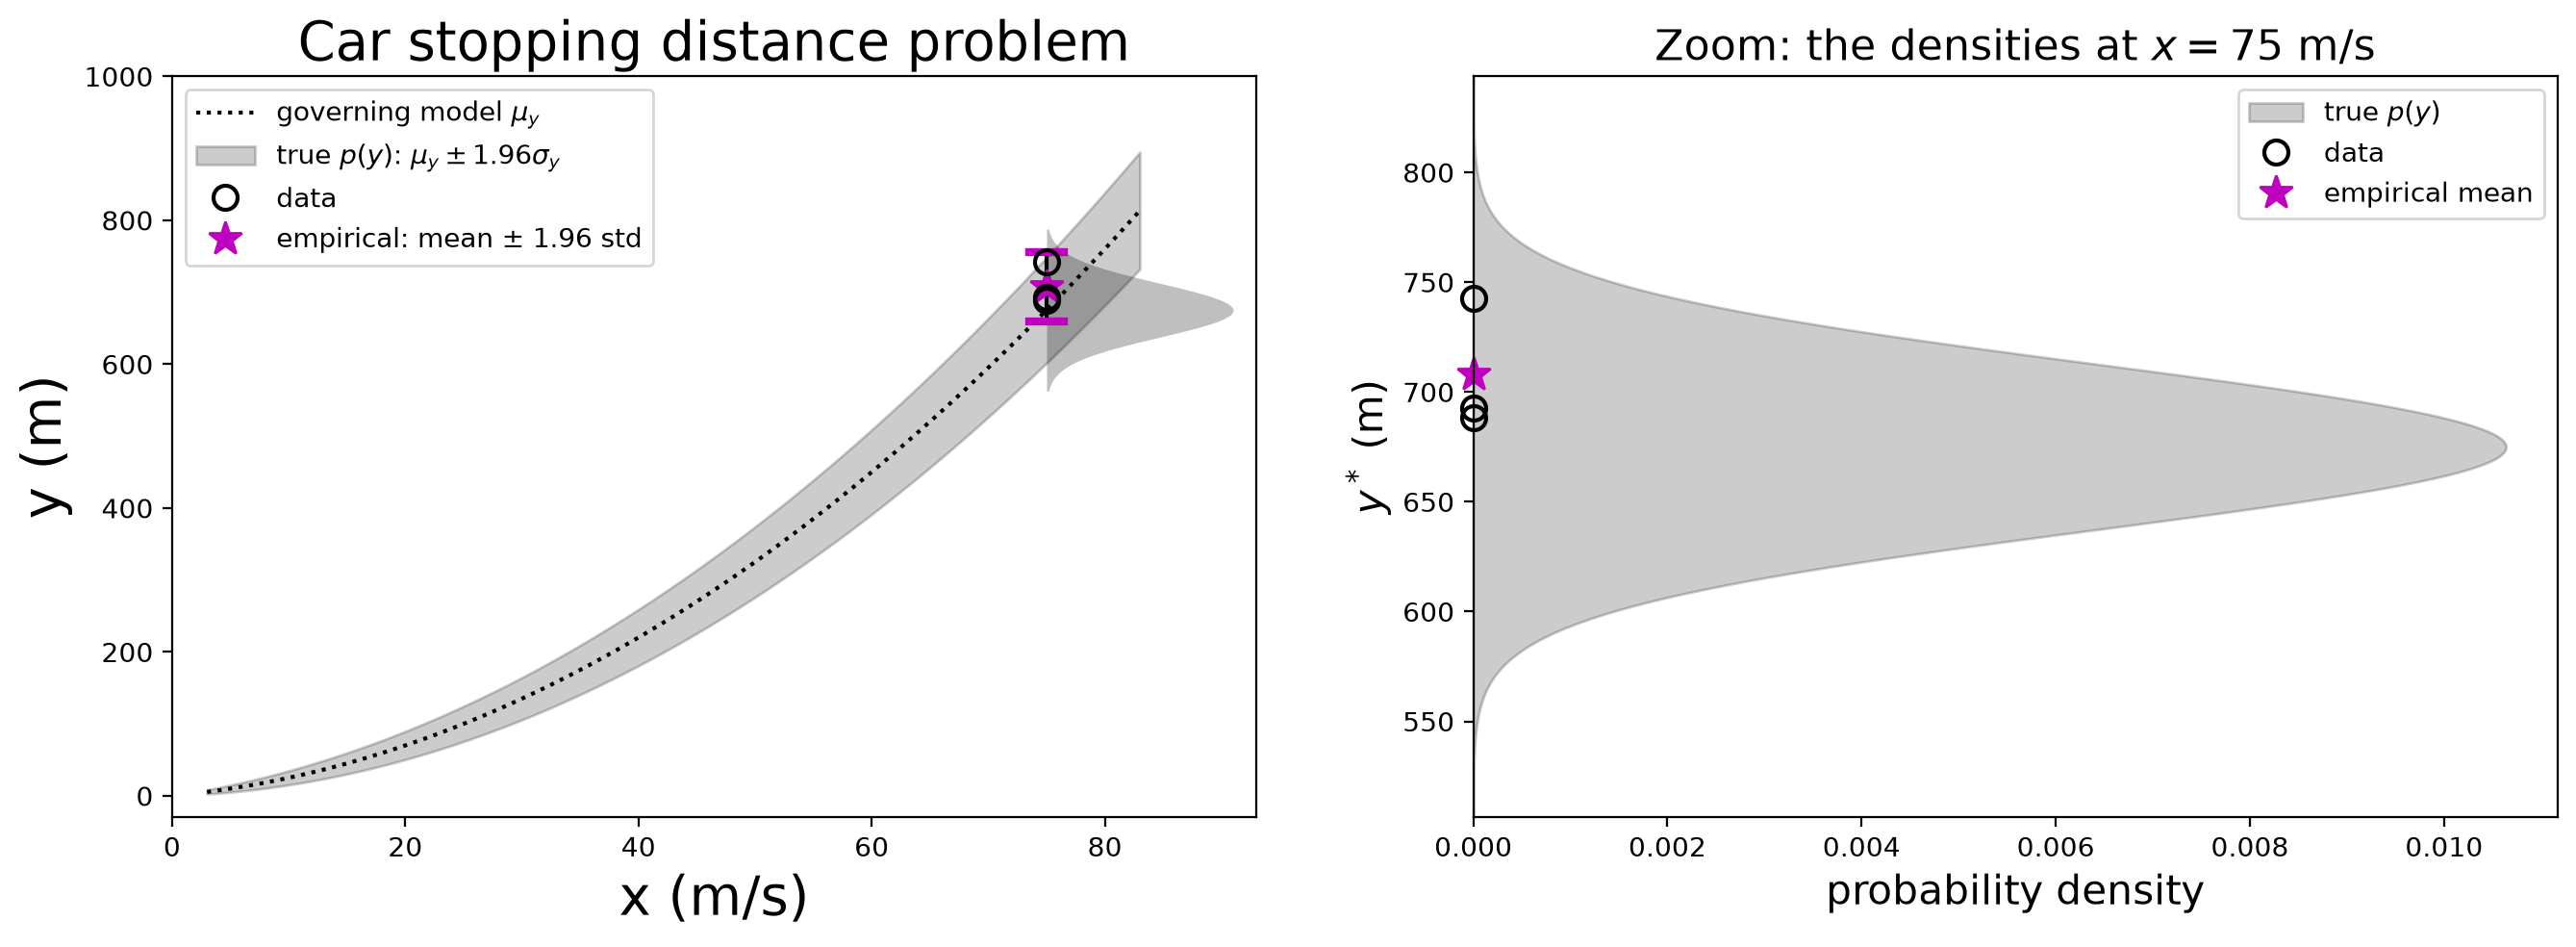

In [5]:
N_samples = 3 # CHANGE THIS NUMBER AND RE-RUN THE CELL
x = 75; empirical_y = samples_y(N_samples, x); # Empirical measurements of N_samples at x=75
empirical_mu_y = np.mean(empirical_y); empirical_sigma_y = np.std(empirical_y); # empirical mean and std
fig_car_new, ax_car_new = plt.subplots(1,2) # two plots: the overview, and a zoom at x
plot_PPDs(ax_car_new, x, empirical_y, []) # a function I created: the data at x, on top of the governing model
print("Empirical mean[y] is",empirical_mu_y, "(real mean[y]=675)")
print("Empirical std[y] is",empirical_sigma_y,"(real std[y]=37.5)")
fig_car_new.set_size_inches(16, 5) # scale figure to be wider (since there are 2 subplots)

## Recap of Lecture 5: Summary of our model

1. The **observation distribution**:

$$
p(y|z) = \mathcal{N}\left(y | \mu_{y|z}=w z+b, \sigma_{y|z}^2\right) = \frac{1}{C_{y|z}} \exp\left[ -\frac{1}{2\sigma_{y|z}^2}(y-\mu_{y|z})^2\right]
$$

where $C_{y|z} = \sqrt{2\pi \sigma_{y|z}^2}$ is the **normalization constant** of the Gaussian pdf, and where $\mu_{y|z}=w z+b$, with $w$, $b$ and $\sigma_{y|z}^2$ being constants.

2. and the **prior distribution**: $p(z) = \frac{1}{C_z}$

where $C_z = z_{max}-z_{min}$ is the **normalization constant** of the Uniform pdf, i.e. the value that guarantees that $p(z)$ integrates to one.

### Recap of Lecture 5: Data

* Since we usually don't know the true process, we can only observe/collect data $y=\mathcal{D}_y$:

In [6]:
print("Example of N=%1i data points for y at x=%1.1f m/s with :" % (N_samples,x), empirical_y)

Example of N=3 data points for y at x=75.0 m/s with : [742.67246729 688.25858233 692.57871492]


## Recap of Lecture 5: Posterior from Bayes' rule applied to data

Use Bayes' rule applied to data to determine the <font color='green'>posterior</font>:

$$
{\color{green}p(z|y=\mathcal{D}_y)} = \frac{ {\color{blue}p(y=\mathcal{D}_y|z)}{\color{red}p(z)} } {p(y=\mathcal{D}_y)}
$$

### Likelihood for car stopping distance problem

As we saw last class, the **likelihood** is obtained by evaluating the **observation distribution** at the data $\mathcal{D}_y$.

Noting that each observation in $\mathcal{D}_y$ is independent of each other and that they have the same distribution (**independent and identically distributed**: i.i.d.), then:

$$
{\color{blue}p(y=\mathcal{D}_y | z)} = \prod_{i=1}^{N} p(y=y_i|z) = p(y=y_1|z)p(y=y_2|z) \cdots p(y=y_N|z)
$$

which gives the **probability density** of observing that data if using our observation distribution (part of our model!).

#### Calculating the likelihood

Let's calculate it:

$$
\begin{align}
{\color{blue}p(y=\mathcal{D}_y | z)} &= \prod_{i=1}^{N} p(y=y_i|z) \\
&= \prod_{i=1}^{N} \frac{1}{|w|}\frac{1}{\sqrt{2\pi \left(\frac{\sigma_{y|z}}{w}\right)^2}} \exp\left\{ -\frac{1}{2\left(\frac{\sigma_{y|z}}{w}\right)^2}\left[z-\left(\frac{y_i-b}{w}\right)\right]^2\right\} \\
&= \prod_{i=1}^{N} \frac{1}{|w|} \mathcal{N}\left(z|\mu_i, \sigma_i^2\right)
\end{align}
$$

where $\mu_i = \frac{y_i-b}{w}$ and $\sigma_i =\frac{\sigma_{y|z}}{w}$

This seems a bit daunting... I know. Do not despair yet!

##### Product of Gaussian pdf's of the same rv $z$

It can be shown that the product of $N$ univariate Gaussian pdf's of the same rv $z$ is:

$$
\prod_{i=1}^{N} \mathcal{N}(z|\mu_i, \sigma_i^2) = C \cdot \mathcal{N}(z|\mu, \sigma^2)
$$

with mean: $\mu = \sigma^2 \left( \sum_{i=1}^{N} \frac{\mu_i}{\sigma_i^2}\right)$

variance: $\sigma^2= \frac{1}{\sum_{i=1}^{N} \frac{1}{\sigma_i^2}}$

and normalization constant: $C = \frac{1}{\left(2\pi\right)^{(N-1)/2}}\sqrt{\frac{\sigma^2}{\prod_{i=1}^N \sigma_i^2}} \exp\left[-\frac{1}{2}\left(\sum_{i=1}^{N} \frac{\mu_i^2}{\sigma_i^2} - \frac{\mu^2}{\sigma^2}\right)\right]$

Curiosity: the normalization constant $C$ is itself a Gaussian! You can see it more clearly if you consider $N=2$

Note that the normalization constant shown in the previous cell can also be written as:

$$
C = \frac{1}{\left(2\pi\right)^{(N-1)/2}}\sqrt{\frac{\sigma^2}{\prod_{i=1}^N \sigma_i^2}} \exp\left[-\frac{1}{2}\left(\sum_{i=1}^{N-1}\sum_{j=i+1}^{N} \frac{(\mu_i-\mu_j)^2}{\sigma_i^2 \sigma_j^2}\sigma^2\right)\right]
$$

## In Homework 3...

Show that the product of two Gaussian <a title="probability density functions">pdf's</a> for the same <a title="random variable">rv</a> $z$ is:

$\mathcal{N}(z|\mu_1, \sigma_1^2)\cdot \mathcal{N}(z|\mu_2, \sigma_2^2)= C \cdot \mathcal{N}(z | \mu, \sigma^2)$

$$
\begin{align}
\sigma^2&=\frac{1}{\frac{1}{\sigma_1^2}+\frac{1}{\sigma_2^2}}\\
\mu&=\sigma^2\left(\frac{\mu_1}{\sigma_1^2} +  \frac{\mu_2}{\sigma_2^2}\right)\\
C &= \frac{1}{\sqrt{2\pi(\sigma_1^2+\sigma_2^2)}} \exp\left[-\frac{1}{2(\sigma_1^2+\sigma_2^2)}(\mu_1-\mu_2)^2\right]
\end{align}
$$

#### Side note

It's interesting to note that the product of MVN's for the same rv's $\mathbf{z}$ is also a Gaussian!

To keep things simple, here's the result for the product of 2 Gaussian pdf's:

$\mathcal{N}(\mathbf{z}|\boldsymbol{\mu}_1, \boldsymbol{\Sigma}_1)\cdot \mathcal{N}(\mathbf{z}|\boldsymbol{\mu}_2, \boldsymbol{\Sigma}_2)= C \cdot \mathcal{N}(\mathbf{z} | \boldsymbol{\mu}, \boldsymbol{\Sigma})$

where

$\boldsymbol{\mu} = \boldsymbol{\Sigma}\left(\boldsymbol{\Sigma}_1^{-1}\boldsymbol{\mu}_1 + \boldsymbol{\Sigma}_2^{-1}\boldsymbol{\mu}_2 \right)$

$\boldsymbol{\Sigma} = \left( \boldsymbol{\Sigma}_1^{-1}+\boldsymbol{\Sigma}_2^{-1}\right)^{-1}$

$
\begin{align}
C &= \mathcal{N}_{\boldsymbol{\mu}_1}\left(\boldsymbol{\mu}_2, \left( \boldsymbol{\Sigma}_1+\boldsymbol{\Sigma}_2\right)\right)\\
&= \frac{1}{\sqrt{\det[2\pi \left( \boldsymbol{\Sigma}_1+\boldsymbol{\Sigma}_2 \right)]}} \exp\left[-\frac{1}{2} \left( \boldsymbol{\mu}_1-\boldsymbol{\mu}_2\right)^T\cdot\left( \boldsymbol{\Sigma}_1+\boldsymbol{\Sigma}_2 \right)^{-1}\left( \boldsymbol{\mu}_1-\boldsymbol{\mu}_2 \right) \right]\\
\end{align}
$

#### Back to calculating the likelihood

$$
\begin{align}
{\color{blue}p(y=\mathcal{D}_y | z)} &= \prod_{i=1}^{N} p(y=y_i|z) \\
&= \prod_{i=1}^{N} \frac{1}{|w|} \frac{1}{\sqrt{2\pi \left(\frac{\sigma_{y|z}}{w}\right)^2}} \exp\left\{ -\frac{1}{2\left(\frac{\sigma_{y|z}}{w}\right)^2}\left[z-\left(\frac{y_i-b}{w}\right)\right]^2\right\} \\
&= \frac{1}{|w|^N} \prod_{i=1}^{N} \frac{1}{\sqrt{2\pi \left(\frac{\sigma_{y|z}}{w}\right)^2}} \exp\left\{ -\frac{1}{2\left(\frac{\sigma_{y|z}}{w}\right)^2}\left[z-\left(\frac{y_i-b}{w}\right)\right]^2\right\}
\end{align}
$$

So, using the result of a product of $N$ Gaussian pdf's to calculate the likelihood, and noting that $\sigma_i = \frac{\sigma_{y|z}}{w}$ and $\mu_i = \frac{y_i - b}{w}$ we get:

$$
{\color{blue}p(y=\mathcal{D}_y | z)} = \frac{1}{|w|^N} \cdot C \cdot \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left[ -\frac{1}{2\sigma^2}(z-\mu)^2\right]
$$

where

$\mu = \frac{\sigma^2}{\sigma_i^2} \sum_{i=1}^N \mu_i = \frac{w^2\sigma^2}{\sigma_{y|z}^2} \sum_{i=1}^N \mu_i$

$\sigma^2 = \frac{1}{ \sum_{i=1}^N \frac{1}{\sigma_i^2} } = \frac{1}{ \sum_{i=1}^N \frac{w^2}{\sigma_{y|z}^2} } = \frac{\sigma_{y|z}^2}{w^2 N}$

$
C = \frac{1}{\left(2\pi\right)^{(N-1)/2}} \sqrt{\frac{\sigma^2}{\left( \frac{\sigma_{y|z}^2}{w^2}\right)^N}} \exp\left[-\frac{1}{2}\left(\frac{w^2}{\sigma_{y|z}^2}\sum_{i=1}^N \mu_i^2 - \frac{\mu^2}{\sigma^2}\right) \right] = \frac{1}{\left(2\pi\right)^{(N-1)/2}} \sqrt{\frac{\sigma^2}{\left( \frac{\sigma_{y|z}^2}{w^2}\right)^N}} \exp\left[-\frac{1}{2\sigma_{y|z}^2}\sum_{i=1}^N \left(y_i-\bar{y}\right)^2\right]
$

where $\bar{y} = \frac{1}{N}\sum_{i=1}^N y_i$ is the mean of the data. (The exponential is not 1: it measures how scattered the data are, and it is the reason the marginal likelihood depends on the data.)

#### Calculating the marginal likelihood and posterior

$$\begin{align}
p(y=\mathcal{D}_y) &= \int p(y=\mathcal{D}_y | z) p(z) dz \\
&= \int \frac{1}{|w|^N} C \cdot \mathcal{N}(z|\mu, \sigma^2)\cdot \frac{1}{C_z} dz\\
&= \frac{C}{|w|^N C_z} \int \mathcal{N}(z|\mu, \sigma^2)dz = \frac{C}{|w|^N C_z} \\
\end{align}
$$

We can now calculate the posterior:

$$\begin{align}
{\color{green}p(z|y=\mathcal{D}_y)} &= \frac{ p(y=\mathcal{D}_y|z)p(z) } {p(y=\mathcal{D}_y)} \\
&= \frac{1}{p(y=\mathcal{D}_y)} \cdot \frac{1}{|w|^N} C \cdot \mathcal{N}(z|\mu,\sigma^2) \cdot \frac{1}{C_z} \\
&= \mathcal{N}(z|\mu, \sigma^2)
\end{align}
$$

## Determining the Posterior Predictive Distribution (<a title="Posterior Predictive Distribution">PPD</a>) from the posterior

However, as we mentioned, Bayes' rule is just a way to calculate the posterior:

$$
{\color{green}p(z|y=\mathcal{D}_y)} = \frac{ p(y=\mathcal{D}_y|z)p(z) } {p(y=\mathcal{D}_y)}
$$

What we really want is the <font color='orange'>Posterior Predictive Distribution (<a title="Posterior Predictive Distribution">PPD</a>)</font> . This comes after calculating the posterior given some data $\mathcal{D}_y$:

$$
{\color{orange}p(y^*|y=\mathcal{D}_y)} = \int p(y^*|z) p(z|y=\mathcal{D}_y) dz
$$

which is often written in simpler notation: $p(y^*|\mathcal{D}_y) = \int p(y^*|z) p(z|\mathcal{D}_y) dz$

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \int \underbrace{p(y^*|z)}_{\substack{\text{observation} \\ \text{distribution}}} \overbrace{p(z|y=\mathcal{D}_y)}^{\text{posterior}} dz
$$

Considering the terms we found before, we get:

$$\begin{align}
p(y^*|\mathcal{D}_y) &= \int \underbrace{\frac{1}{|w|}\frac{1}{\sqrt{2\pi \left(\frac{\sigma_{y|z}}{w}\right)^2}} \exp\left\{ -\frac{1}{2\left(\frac{\sigma_{y|z}}{w}\right)^2}\left[z-\left(\frac{y^*-b}{w}\right)\right]^2\right\} }_{\text{observation distribution}} \overbrace{\mathcal{N}(z|\mu, \sigma^2)}^{\text{posterior}} dz
\end{align}
$$

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \frac{1}{|w|} \int {\color{blue}\frac{1}{\sqrt{2\pi \left(\frac{\sigma_{y|z}}{w}\right)^2}} \exp\left\{ -\frac{1}{2\left(\frac{\sigma_{y|z}}{w}\right)^2}\left[z-\left(\frac{y^*-b}{w}\right)\right]^2\right\}} \mathcal{N}(z|\mu, \sigma^2) dz
$$

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \frac{1}{|w|} \int \mathcal{N}\left(z\left|\frac{y^*-b}{w}, \left(\frac{\sigma_{y|z}}{w}\right)^2\right.\right) \mathcal{N}(z|\mu, \sigma^2) dz
$$

This is (again!) the product of two Gaussians!

In the beginning of this lecture (and the Homework!) you saw (and will demonstrate!) that the product of two or more univariate (and multivariate!) Gaussians is...

* Another Gaussian! Although it needs to be scaled by a constant...

So, we conclude that the <a title="Posterior Predictive Distribution">PPD</a> is an integral of a Gaussian:

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \frac{1}{|w|} \int  \tilde{C} \mathcal{N}\left(z|\tilde{\mu}, \left(\tilde{\sigma}\right)^2\right) dz
$$


where $\tilde{\mu} = \left(\tilde{\sigma} \right)^2 \left( \frac{\mu}{\sigma^2} + \frac{(y^*-b)/w}{\left(\frac{\sigma_{y|z}}{w}\right)^2} \right) = \left(\tilde{\sigma} \right)^2 \left( \frac{\mu}{\sigma^2} + \frac{(y^*-b)\cdot w}{\sigma_{y|z}^2} \right)$

$\left( \tilde{\sigma} \right)^2 = \frac{1}{\frac{1}{\sigma^2}+\frac{1}{\left( \frac{\sigma_{y|z}}{w}\right)^2}}= \frac{1}{\frac{1}{\sigma^2}+\frac{w^2}{\sigma_{y|z}^2}}$

$\tilde{C} = \frac{1}{\sqrt{2\pi \left( \sigma^2 + \frac{\sigma_{y|z}^2}{w^2} \right)}}\exp\left[ - \frac{\left(\mu - \frac{y^*-b}{w}\right)^2}{2\left( \sigma^2+\frac{\sigma_{y|z}^2}{w^2}\right)}\right]$

This integral is simple to solve!

$$
\begin{align}
{\color{orange}p(y^*|\mathcal{D}_y)} &= \frac{1}{|w|} \int  \tilde{C} \mathcal{N}\left(z|\tilde{\mu}, \left(\tilde{\sigma}\right)^2\right) dz \\
&= \frac{\tilde{C}}{|w|} \int   {\color{purple}\mathcal{N}\left(z|\tilde{\mu}, \left(\tilde{\sigma}\right)^2\right)} dz
\end{align}
$$

What's the result of integrating the <font color='purple'>purple</font> term?

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \frac{\tilde{C}}{|w|}
$$

## In Homework 3 (exercise 2)

Rewrite the <a title="Posterior Predictive Distribution">PPD</a> to show that it becomes:

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \mathcal{N}\left(y^*| b+\mu w, w^2\sigma^2+\sigma_{y|z}^2 \right)
$$

a normalized univariate Gaussian!

## A long way to show that the <a title="Posterior Predictive Distribution">PPD</a> is a simple Gaussian...

$$
{\color{orange}p(y^*|\mathcal{D}_y)} = \mathcal{N}\left(y^*| b+\mu w, w^2\sigma^2+\sigma_{y|z}^2 \right)
$$

where we recall that each constant is:

$b = 0.1x^2 = 562.5$

$w = x = 75$

$\sigma_{y|z}^2 = s^2 = 80^2$

$\sigma^2 = \frac{\sigma_{y|z}^2}{w^2 N} = \frac{s^2}{w^2 N} $

$\mu = \frac{w^2 \sigma^2}{\sigma_{y|z}^2} \sum_{i=1}^{N} \mu_i = \cdots = \frac{\sum_{i=1}^N y_i}{w N}-\frac{b}{w}$


#### Note on algebra to determine $\mu$ parameter:

$$
\begin{align}
\mu &= \frac{w^2 \sigma^2}{\sigma_{y|z}^2} \sum_{i=1}^{N} \mu_i \\
&= \frac{\sum_{i=1}^{N} \mu_i}{N} = \frac{1}{N} \sum_{i=1}^{N} \left(\frac{y_i-b}{w}\right) \\
&= \frac{1}{w N} \sum_{i=1}^N\left( y_i-b\right) \\
&= \frac{1}{w N} \left( \sum_{i=1}^N y_i-N b\right) \\
& = \frac{\sum_{i=1}^N y_i}{w N}-\frac{b}{w}
\end{align}
$$

## A long way to show that the <a title="Posterior Predictive Distribution">PPD</a> is a simple Gaussian...

$$
\begin{align}
{\color{orange}p(y^*|\mathcal{D}_y)} &= \mathcal{N}\left(y^*| b+\mu w, w^2\sigma^2+\sigma_{y|z}^2 \right) \\
&= \mathcal{N}\left(y^* \left| \left(\sum_{i=1}^N \frac{y_i}{N}\right), \sigma_{y|z}^2 \left(\frac{1}{N} + 1 \right) \right. \right)
\end{align}
$$

where $y_i$ are each of the $N$ data points of the observed data $\mathcal{D}_y$, and $\sigma_{y|z}^2 = s^2 = 80^2$ is the **variance we assumed** because we were not sure about the governing equation for $y$.

* **Very Important Questions (VIQs)**: What does this result tell us? Did you expect this predicted distribution for $y^*$?

PPD & empirical mean[y] tend to the same value: 682.4202081504778 (real mean[y]=675)
PPD std[y] we predict is 92.37604307034012 & empirical std[y] is 27.89160453541582 (real std[y]=37.5)


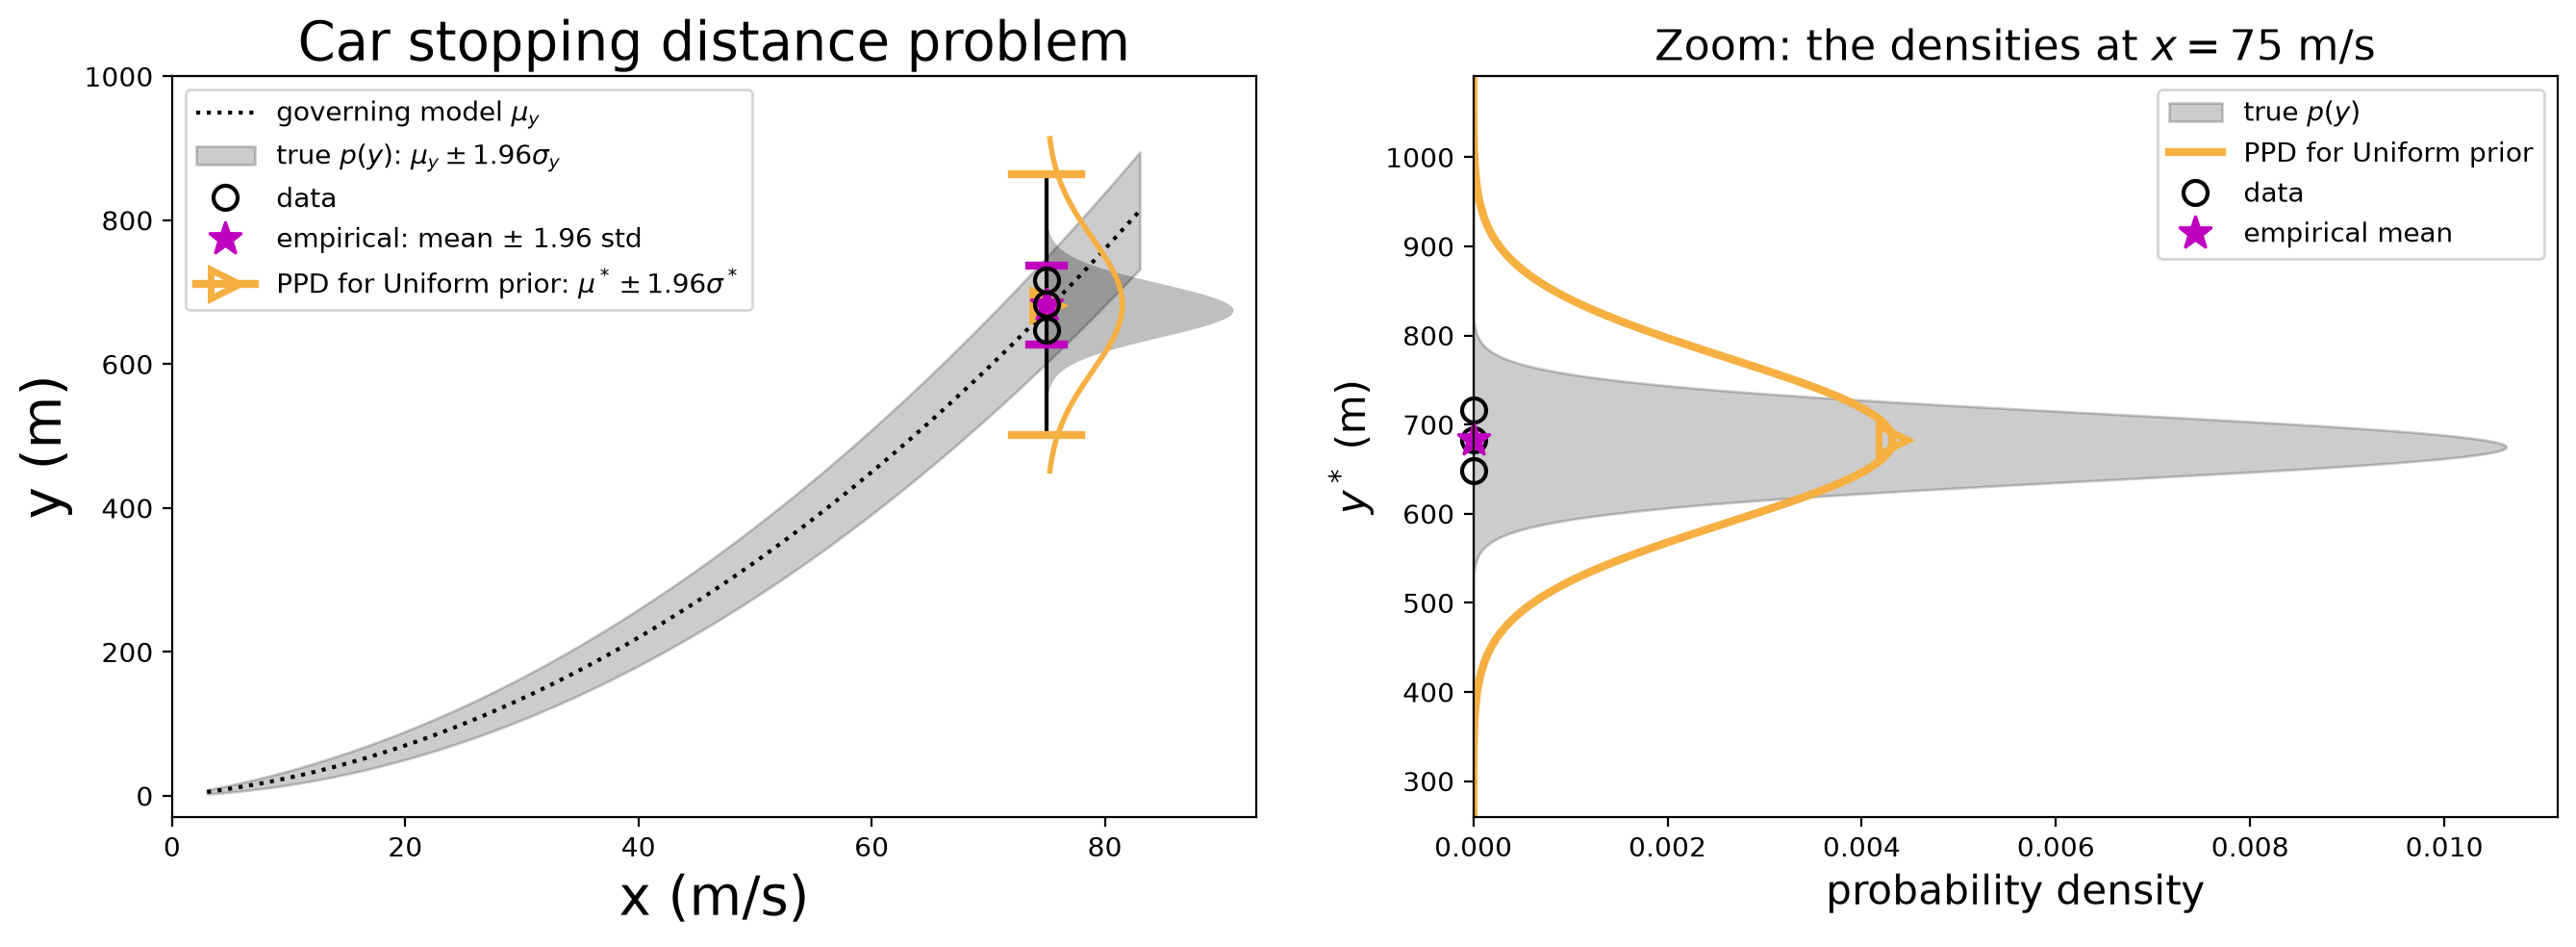

In [7]:
N_samples = 3 # CHANGE THIS NUMBER AND RE-RUN THE CELL
x = 75; empirical_y = samples_y(N_samples, x); # Empirical measurements of N_samples at x=75
empirical_mu_y = np.mean(empirical_y); empirical_sigma_y = np.std(empirical_y); # empirical mean and std
# Calculate PPD mean and standard deviation:
PPD_mu_y = np.mean(empirical_y); sigma_yGIVENz = 80; PPD_sigma_y = np.sqrt( sigma_yGIVENz**2*(1/N_samples + 1) )
fig_car_PPD, ax_car_PPD = plt.subplots(1,2) # two plots: the overview, and a zoom at x
plot_PPDs(ax_car_PPD, x, empirical_y, [dict(mu=PPD_mu_y, sigma=PPD_sigma_y, color=col_p['ppd_U'], ls=style['ls_B'],
                                             marker=style['ppd_B'], half='short', label='PPD for Uniform prior')])
print("PPD & empirical mean[y] tend to the same value:",empirical_mu_y, "(real mean[y]=675)")
print("PPD std[y] we predict is",PPD_sigma_y, "& empirical std[y] is",empirical_sigma_y,"(real std[y]=37.5)")
fig_car_PPD.set_size_inches(16, 5) # scale figure to be wider (since there are 2 subplots)

#### Note: which intervals are in this figure?

* **Grey band** (and the grey density at $x=75$ m/s): the central 95% interval of the *true* $p(y)$. We only know it because we are cheating (we know the governing model).
* **Magenta lines** (around the magenta star): the empirical 95% interval, i.e. a plug-in estimate from the $N$ measurements (empirical mean $\pm 1.96\times$ empirical std), as in Lecture 3.
* **Orange lines** (around the orange triangle, and the orange density): the 95% **posterior predictive interval**, $\bar{y} \pm 1.96\,\sigma_{y|z}\sqrt{1+1/N}$: a probability statement about a *new* measurement $y^*$, given this dataset and our model.

Numerically, the orange interval is **identical** to the frequentist 95% **prediction interval** for a new observation when the noise standard deviation is known: $\bar{y} \pm 1.96\,\sigma_{y|z}\sqrt{1+1/N}$. The same happens for the hidden rv: the posterior $\mathcal{N}(z|\mu,\sigma^2)$ gives a 95% **credible interval** $\mu \pm 1.96\,\sigma$ that coincides with the frequentist 95% **confidence interval** for $z$. Same numbers, different meaning: the Bayesian intervals are probabilities given *this* dataset; the frequentist ones describe a procedure over repeated datasets. This numerical coincidence is special to the Uniform prior: the Gaussian prior of the next lecture breaks it.

**An interval is only as honest as the model behind it.** The orange interval uses our assumed $\sigma_{y|z} = 80$ m, which is significantly above the true standard deviation (37.5 m, Lecture 5). So it stays wider than the grey band (and the orange density stays wider than the grey one) no matter how many data points we collect: a correctly computed interval from a wrong model is still wrong.

### Reflection on what we are observing

1. Generally speaking, our PPD is quite reasonable and the result should be intuitive!
    * For few data points, the variance of the PPD is a bit larger than the variance we assumed for the conditional pdf $p(y|z)$, i.e. $\sigma_{y|z}^2=s^2=80^2$.

2. As the number of data points increases (see PPD as $N\rightarrow \infty$ or play with the figure above by increasing $N$), then the variance of the PPD $(\sigma^*)^2 \rightarrow s^2=80^2$ tends to the variance we assumed for our model: $\sigma_{y|z}^2=s^2=80^2$.
    * This results from our choice of likelihood and prior... Our model was incorrect in both:
        * The hidden rv $z$ is actually a Gaussian distribution, instead of a noninformative Uniform distribution
        * The real conditional pdf is the Dirac "distribution" around value $y = zx + 0.1 x^2$, instead of the Gaussian distribution with a mean of $\mu_{y|z}= zx + 0.1 x^2$ and a variance of $\sigma_{y|z}^2 = s^2 = 80^2$.

Please keep this in your head:
* (Bayesian) ML is not magic. Every modeling choice you make affects the predictions you get.
* Of course, there are ways of getting "closer" to the truth! We'll take steps in that direction in the remainder of the course. 

## Next lecture we will redo everything but for a different prior distribution

Consider the same problem, but now starting from a different model:

1. Same **observation distribution** as before:

$$
p(y|z) = \mathcal{N}\left(y | \mu_{y|z}=w z+b, \sigma_{y|z}^2\right) = \frac{1}{C_{y|z}} \exp\left[ -\frac{1}{2\sigma_{y|z}^2}(y-\mu_{y|z})^2\right]
$$

2. <font color='red'>but now assuming a different **prior distribution**</font>: $p(z) = \mathcal{N}\left(z| \overset{\scriptscriptstyle <}{\mu}_z=3, \overset{\scriptscriptstyle <}{\sigma}_z^2=2^2
\right)$

In my notation, the superscript $\overset{\scriptscriptstyle <}{(\cdot)}$ indicates a parameter of the prior distribution.

## Field guide: what this lecture adds

### Key concepts

**Probability**
- **Gaussians are closed under the operations of Bayesian inference**: if variables are jointly Gaussian, their marginals and conditionals are Gaussian; the product of two Gaussian pdfs is proportional to a Gaussian pdf; and a linear transformation of a Gaussian is Gaussian. So if the observation distribution is Gaussian with a mean that is linear in the unknowns (and a known noise), a Gaussian prior gives a Gaussian posterior and a Gaussian PPD. Careful: the product of two Gaussian random variables, or a nonlinear transformation of one, is not Gaussian. Covariance and correlation measure only linear dependence.

**Bayesian inference**
- **The likelihood of i.i.d. data** is the product of the observation distributions at the data points.
- **Predictions come from the posterior predictive distribution (PPD)**, which integrates the unknowns out against the posterior. Its variance has the noise of the data (aleatoric uncertainty) plus the uncertainty about the unknowns (epistemic uncertainty), which shrinks as $1/N$.
- **Credible, confidence and prediction intervals** answer different questions.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Have fun!